# Практическая работа 7.1. Подготовка датасета Wonders of the World

В notebook скачивается датасет с Kaggle, показывается состав классов и создается подготовленный набор данных в формате `train / val / test` для кода из методички по transfer learning.


## Импорты


In [1]:
from __future__ import annotations

import os
from pathlib import Path

PRACTICE_DIR = Path.cwd()
CACHE_DIR = PRACTICE_DIR / ".cache"
DATA_DIR = PRACTICE_DIR / ".data"
MPL_CACHE_DIR = CACHE_DIR / "matplotlib"

for directory in (CACHE_DIR, DATA_DIR, MPL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["MPLCONFIGDIR"] = str(MPL_CACHE_DIR)


In [2]:
import random
import shutil

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SEED = 42
IMAGE_SIZE = (224, 224)
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)

DATASET_HANDLE = "balabaskar/wonders-of-the-world-image-classification"
SOURCE_DATASET_DIR = DATA_DIR / "wonders-of-world-source"
PREPARED_DATASET_DIR = DATA_DIR / "wonders-of-world-prepared"
DATASET_ROOT = SOURCE_DATASET_DIR / "Wonders of World" / "Wonders of World"

random.seed(SEED)
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

if not np.isclose(sum(SPLIT_FRACTIONS), 1.0):
    raise ValueError("Сумма долей train, val и test должна быть равна 1.")


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Описание данных

В работе используется датасет `Wonders of the World Image Classification`. Внутри него `12` классов с фотографиями известных архитектурных и природных объектов. Для обучения в PyTorch данные будут перепакованы в структуру `train / val / test`.


## Загрузка датасета


In [3]:
def download_dataset_if_needed(
    source_dataset_dir: Path,
    dataset_root: Path,
    dataset_handle: str,
) -> None:
    """
    Скачивает датасет Kaggle, если локальная копия еще не подготовлена.

    Parameters
    ----------
    source_dataset_dir : Path
        Каталог для скачивания датасета.
    dataset_root : Path
        Каталог с папками классов.
    dataset_handle : str
        Идентификатор датасета на Kaggle.
    """
    if dataset_root.is_dir():
        return

    kagglehub.dataset_download(
        dataset_handle,
        output_dir=str(source_dataset_dir),
    )


In [4]:
def collect_class_images(dataset_root: Path) -> dict[str, list[Path]]:
    """
    Собирает пути к изображениям по всем классам датасета.

    Parameters
    ----------
    dataset_root : Path
        Каталог с папками классов.

    Returns
    -------
    dict[str, list[Path]]
        Словарь с изображениями по классам.
    """
    image_suffixes = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    class_to_images: dict[str, list[Path]] = {}

    for class_directory in sorted(path for path in dataset_root.iterdir() if path.is_dir()):
        image_paths = sorted(
            image_path
            for image_path in class_directory.iterdir()
            if image_path.is_file() and image_path.suffix.lower() in image_suffixes
        )

        if image_paths:
            class_to_images[class_directory.name] = image_paths

    if not class_to_images:
        raise FileNotFoundError("Не удалось найти изображения в исходном датасете.")

    return class_to_images


In [5]:
download_dataset_if_needed(
    SOURCE_DATASET_DIR,
    DATASET_ROOT,
    DATASET_HANDLE,
)

class_to_images = collect_class_images(DATASET_ROOT)
class_names = sorted(class_to_images)
class_counts = np.asarray(
    [len(class_to_images[class_name]) for class_name in class_names],
    dtype=np.int64,
)

print(f"Количество изображений: {int(class_counts.sum())}")
print(f"Количество классов: {len(class_names)}")
print("Классы:", class_names)


Количество изображений: 3846
Количество классов: 12
Классы: ['burj_khalifa', 'chichen_itza', 'christ_the_reedemer', 'eiffel_tower', 'great_wall_of_china', 'machu_pichu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty', 'stonehenge', 'taj_mahal', 'venezuela_angel_falls']


## Обзор данных


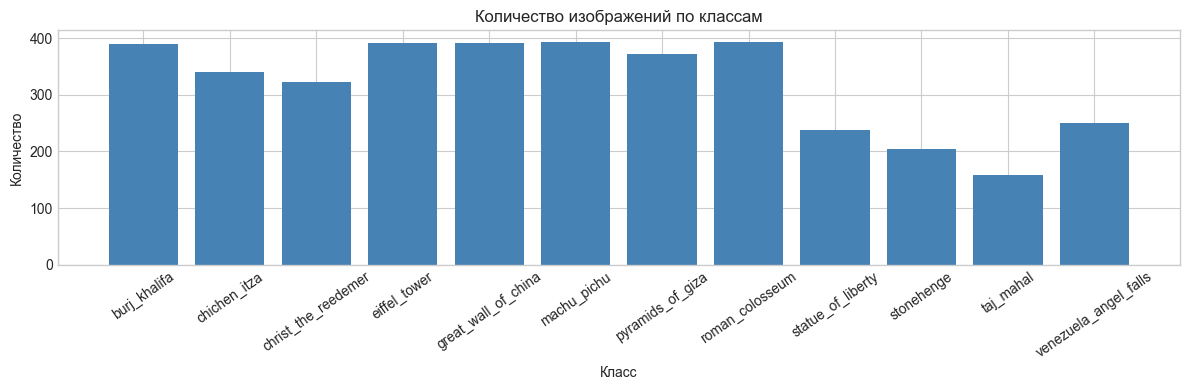

In [6]:
fig, axis = plt.subplots(figsize=(12, 4))
axis.bar(class_names, class_counts, color="steelblue")
axis.set_title("Количество изображений по классам")
axis.set_xlabel("Класс")
axis.set_ylabel("Количество")
axis.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


In [7]:
def show_preview(
    class_to_images: dict[str, list[Path]],
    class_names: list[str],
    image_size: tuple[int, int],
    *,
    num_images: int = 12,
) -> None:
    """
    Показывает несколько исходных изображений из датасета.

    Parameters
    ----------
    class_to_images : dict[str, list[Path]]
        Изображения, сгруппированные по классам.
    class_names : list[str]
        Названия классов.
    image_size : tuple[int, int]
        Размер изображения для превью.
    num_images : int
        Количество изображений в превью.
    """
    all_image_paths = [
        image_path
        for class_name in class_names
        for image_path in class_to_images[class_name]
    ]
    all_labels = [
        class_name
        for class_name in class_names
        for _ in class_to_images[class_name]
    ]

    preview_size = min(num_images, len(all_image_paths))
    preview_indices = random.sample(range(len(all_image_paths)), k=preview_size)

    fig, axes = plt.subplots(3, 4, figsize=(11, 8))
    axes = np.asarray(axes).reshape(-1)

    for axis, image_index in zip(axes, preview_indices):
        image = Image.open(all_image_paths[image_index]).convert("RGB")
        image = image.resize(image_size)
        axis.imshow(image)
        axis.set_title(all_labels[image_index], fontsize=9)
        axis.axis("off")

    for axis in axes[preview_size:]:
        axis.axis("off")

    plt.tight_layout()
    plt.show()


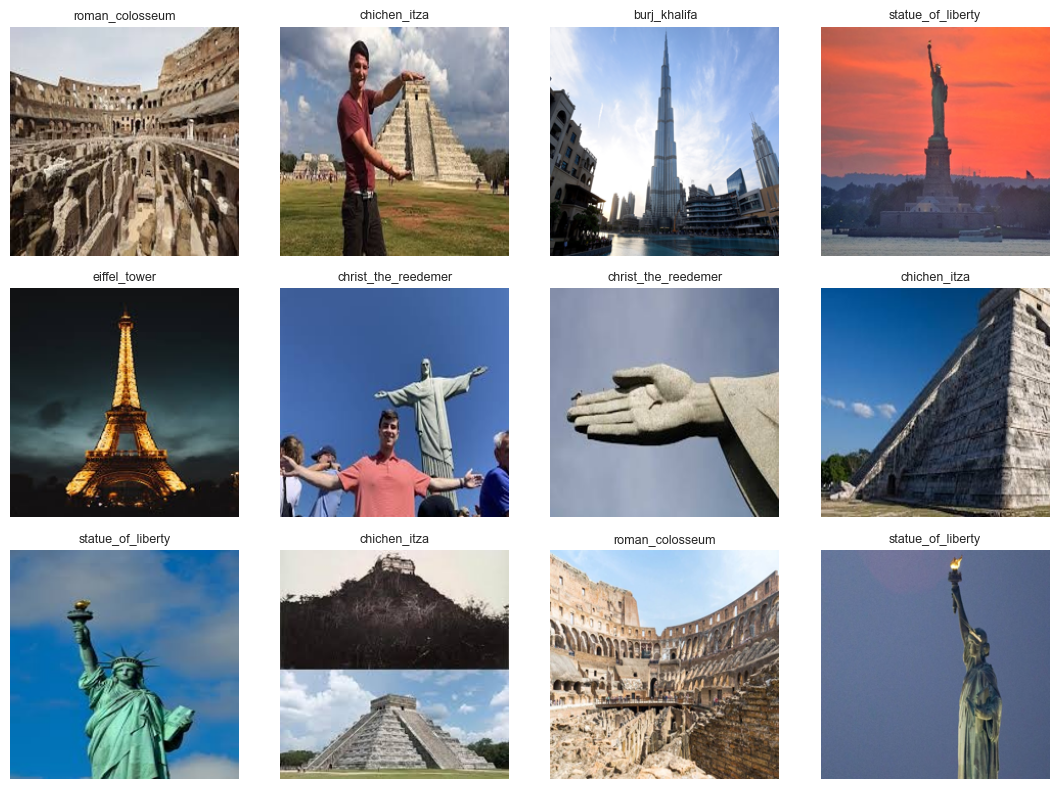

In [8]:
show_preview(
    class_to_images,
    class_names,
    IMAGE_SIZE,
)


## Разбиение на train / val / test

Разбиение выполняется отдельно внутри каждого класса. Это сохраняет представление каждого класса во всех выборках.


In [9]:
def build_split_records(
    class_to_images: dict[str, list[Path]],
    split_fractions: tuple[float, float, float],
    seed: int,
) -> dict[str, dict[str, list[Path]]]:
    """
    Делит изображения каждого класса на train, val и test.

    Parameters
    ----------
    class_to_images : dict[str, list[Path]]
        Изображения, сгруппированные по классам.
    split_fractions : tuple[float, float, float]
        Доли train, val и test.
    seed : int
        Начальное значение генератора случайных чисел.

    Returns
    -------
    dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и по классам.
    """
    train_fraction, val_fraction, _ = split_fractions
    split_records = {"train": {}, "val": {}, "test": {}}

    for class_index, class_name in enumerate(sorted(class_to_images)):
        image_paths = list(class_to_images[class_name])
        random.Random(seed + class_index).shuffle(image_paths)

        total = len(image_paths)
        train_size = int(total * train_fraction)
        val_size = int(total * val_fraction)

        split_records["train"][class_name] = image_paths[:train_size]
        split_records["val"][class_name] = image_paths[train_size:train_size + val_size]
        split_records["test"][class_name] = image_paths[train_size + val_size:]

    return split_records


In [10]:
split_records = build_split_records(
    class_to_images,
    SPLIT_FRACTIONS,
    SEED,
)

split_class_counts = {
    split_name: {
        class_name: len(paths)
        for class_name, paths in class_records.items()
    }
    for split_name, class_records in split_records.items()
}
split_sizes = {
    split_name: sum(class_counts.values())
    for split_name, class_counts in split_class_counts.items()
}

for split_name, class_counts in split_class_counts.items():
    print(f"\n{split_name}:")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count}")
    print(f"  total: {split_sizes[split_name]}")



train:
  burj_khalifa: 273
  chichen_itza: 237
  christ_the_reedemer: 226
  eiffel_tower: 273
  great_wall_of_china: 274
  machu_pichu: 275
  pyramids_of_giza: 260
  roman_colosseum: 275
  statue_of_liberty: 166
  stonehenge: 142
  taj_mahal: 110
  venezuela_angel_falls: 175
  total: 2686

val:
  burj_khalifa: 58
  chichen_itza: 51
  christ_the_reedemer: 48
  eiffel_tower: 58
  great_wall_of_china: 58
  machu_pichu: 58
  pyramids_of_giza: 55
  roman_colosseum: 59
  statue_of_liberty: 35
  stonehenge: 30
  taj_mahal: 23
  venezuela_angel_falls: 37
  total: 570

test:
  burj_khalifa: 59
  chichen_itza: 52
  christ_the_reedemer: 49
  eiffel_tower: 60
  great_wall_of_china: 60
  machu_pichu: 60
  pyramids_of_giza: 57
  roman_colosseum: 60
  statue_of_liberty: 37
  stonehenge: 32
  taj_mahal: 25
  venezuela_angel_falls: 39
  total: 590


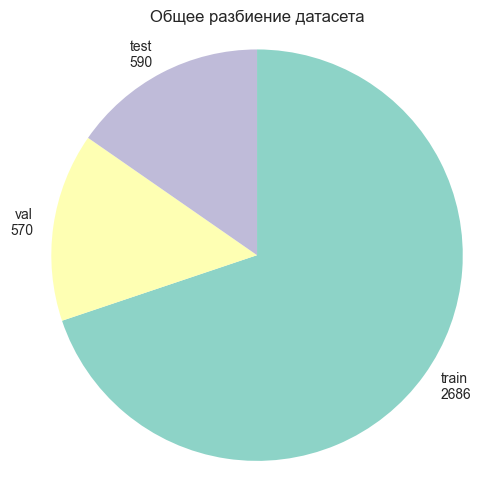

In [11]:
fig, axis = plt.subplots(figsize=(5, 5))
axis.pie(
    list(split_sizes.values()),
    labels=[f"{name}\n{size}" for name, size in split_sizes.items()],
    startangle=90,
    counterclock=False,
)
axis.set_title("Общее разбиение датасета")
axis.axis("equal")
plt.tight_layout()
plt.show()


## Сохранение подготовленного датасета


In [12]:
def create_prepared_dataset(
    prepared_dir: Path,
    split_records: dict[str, dict[str, list[Path]]],
) -> None:
    """
    Копирует изображения в структуру train / val / test для ImageFolder.

    Parameters
    ----------
    prepared_dir : Path
        Каталог для подготовленного датасета.
    split_records : dict[str, dict[str, list[Path]]]
        Пути к изображениям по split и по классам.
    """
    if prepared_dir.exists():
        shutil.rmtree(prepared_dir)

    for split_name, class_records in split_records.items():
        for class_name, paths in class_records.items():
            target_dir = prepared_dir / split_name / class_name
            target_dir.mkdir(parents=True, exist_ok=True)

            for index, source_path in enumerate(paths, start=1):
                target_name = f"{class_name}_{source_path.stem}_{index:05d}{source_path.suffix.lower()}"
                shutil.copy2(source_path, target_dir / target_name)


In [13]:
create_prepared_dataset(PREPARED_DATASET_DIR, split_records)
print(PREPARED_DATASET_DIR)


/Users/mikhail/Developer/SUSU.PE/СП-М-О-КЗ-2025/Практика/Практика 7 - Перенос обучения PyTorch/.data/wonders-of-world-prepared


In [14]:
for split_name in ("train", "val", "test"):
    split_dir = PREPARED_DATASET_DIR / split_name
    total = 0
    print(f"\n{split_name}:")
    for class_dir in sorted(path for path in split_dir.iterdir() if path.is_dir()):
        count = len(list(class_dir.rglob("*.*")))
        total += count
        print(f"  {class_dir.name}: {count}")
    print(f"  total: {total}")



train:
  burj_khalifa: 273
  chichen_itza: 237
  christ_the_reedemer: 226
  eiffel_tower: 273
  great_wall_of_china: 274
  machu_pichu: 275
  pyramids_of_giza: 260
  roman_colosseum: 275
  statue_of_liberty: 166
  stonehenge: 142
  taj_mahal: 110
  venezuela_angel_falls: 175
  total: 2686

val:
  burj_khalifa: 58
  chichen_itza: 51
  christ_the_reedemer: 48
  eiffel_tower: 58
  great_wall_of_china: 58
  machu_pichu: 58
  pyramids_of_giza: 55
  roman_colosseum: 59
  statue_of_liberty: 35
  stonehenge: 30
  taj_mahal: 23
  venezuela_angel_falls: 37
  total: 570

test:
  burj_khalifa: 59
  chichen_itza: 52
  christ_the_reedemer: 49
  eiffel_tower: 60
  great_wall_of_china: 60
  machu_pichu: 60
  pyramids_of_giza: 57
  roman_colosseum: 60
  statue_of_liberty: 37
  stonehenge: 32
  taj_mahal: 25
  venezuela_angel_falls: 39
  total: 590
